In [2]:
import math
import numpy as np
from math import sin, cos
import matplotlib.pyplot as plt
from scipy.integrate import simpson

from scipy.integrate import quad
from numpy.testing import assert_allclose


### Задание 1. Двухточечная квадратура Гаусса.

Постройте квадратурную формулу Гаусса, интегрирующую точно многочлены степеней вплоть до третьей на интервале $[a, b]$. Заметим, что для этого достаточно построить *двухточечную* квадратуру.

Напишите функцию, которая возвращает веса, $w_1$ и $w_2$, и узлы, $x_1$ и $x_2$, двухточечной квадратурной формулы Гаусса с весовой функцией $w(x) = 1$, т.е., интегралы вида
$$ \int_a^b f(x) \, dx \approx w_1 f(x_1) + w_2 f(x_2) $$

In [3]:
def gauss_2(a, b):
    r"""Return nodes and weights for a two-point Gauss quadrature on[a, b].

    Parameters
    ----------
    a, b : float
        Boundaries of the integration interval

    Returns
    -------
    x1, x2, w1, w2 : float
        Nodes and weights of the quadrature.
    """

    t1 = -1.0 / math.sqrt(3)
    t2 = 1.0 / math.sqrt(3)

    w_tilde = 1.0

    x1 = (b + a) / 2.0 + (b - a) / 2.0 * t1
    x2 = (b + a) / 2.0 + (b - a) / 2.0 * t2

    w1 = (b - a) / 2.0 * w_tilde
    w2 = (b - a) / 2.0 * w_tilde

    return x1, x2, w1, w2

In [4]:
x1, x2, w1, w2 = gauss_2(0, 1)

def f(x, n):
    return x**n

for n in [0, 1, 2, 3]:
    assert_allclose(w1*f(x1, n=n) + w2*f(x2, n=n),
                    1./(n+1), atol=1e-14)

### Задание 2. Вычитание интегрируемых сингулярностей.

Вычислите определённый интеграл методом трапеций с вычитанием сингулярности

$$ I = \int_0^1 \frac{e^x}{\sqrt{x(1 - x)}} \, dx. $$

Вам могут пригодиться значения следующих определенных интегралов:

$$ \int_0^1 \frac{1}{\sqrt{x(1 - x)}} \, dx = \pi, \quad \int_0^1 \frac{x}{\sqrt{x(1 - x)}} \, dx = \pi/2. $$

Преобразуйте данный интеграл, вычитая сингулярности. Выпишите расчетные формулы. Составьте функцию, возвращающую значение интеграла методом трапеций. Проверьте точность ответа методом Рунге.

In [5]:
def integ(npts=10):
    """Compute the value of the integral above.

    Subtract the singularities and use the trapezoid rule.

    Parameters
    ----------
    npts : int
        The number of points for the trapezoid rule

    Returns
    -------
    I : float
        The computed value of the integral
    """
    analytic_part = np.pi * (np.exp(1.0) + 1.0) / 2.0

    x = np.linspace(0, 1, npts)
    dx = x[1] - x[0]

    x_in = x[1:-1]
    f_reg = (np.exp(x_in) - 1.0 - (np.exp(1.0) - 1.0) * x_in) / np.sqrt(x_in * (1.0 - x_in))

    integral_num = dx * np.sum(f_reg)

    return analytic_part + integral_num

In [6]:
#тест
def exact_integrand(x):
    return np.exp(x) / np.sqrt(x * (1.0 - x))


expected_val, _ = quad(exact_integrand, 0, 1)

calc_val = integ(npts=1000)

assert_allclose(calc_val, expected_val, rtol=1e-5)
print("gg")

gg


### Задание 3*. Интеграл от осциллирующей функции.

Рассмотрим определенный интеграл

$$ I = \int_0^\infty \frac{\sin(x) \cos(\cos(x))}{x} \, dx $$

Вычислите значение данного интеграла с относительной точностью $10^{-6}$. Для упрощения задачи можете воспользоваться функционалом `scipy.integrate.quad`.

Заметим, что «из коробки» интеграл вычислить не удается, и нужно что-то придумать. И даже wolfram тут даёт неправильный ответ.

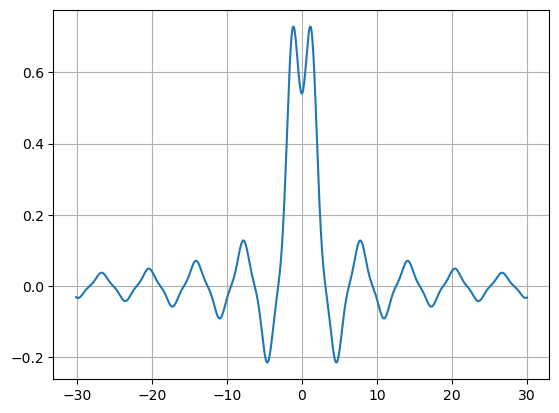

In [7]:
x = np.linspace(-30.1, 30., 1001)
y = np.sin(x) * np.cos(np.cos(x)) / x

plt.plot(x, y)
plt.grid(True)
plt.show()

формула интеграла Лобачевского

In [8]:
def compute_integral():
    def f(x):
        return np.cos(np.cos(x))
    I_val, err = quad(f, 0, np.pi / 2, epsrel=1e-6)
    return I_val


result = compute_integral()
print(result)

1.2019697153172066


### Задание 4. Вычисление интеграла с внутренней особенностью.

Найти аналитически левую и правую окрестности нуля $\delta_1$ и $\delta_2$ такие, чтобы при вычислении интеграла

$$ J = \int_{-0,5}^{0,5} |x|^{-\frac{1}{2}} \cdot (1 - x)^{-\frac{1}{2}} \, dx $$

модуль $|\rho| < \varepsilon$, где $\varepsilon$ — требуемая точность расчетов (см. теорию ранее).


1. Оценка вблизи нуля: Функция ведет себя как $|x|^{-1/2}$. Интеграл от «хвоста» вблизи нуля:
   $$\int_0^\delta \frac{dx}{\sqrt{x}} = 2\sqrt{\delta}$$
2. Общая погрешность $\rho$: Состоит из левой ($\delta_1$) и правой ($\delta_2$) окрестностей:
   $$|\rho| \approx 2\sqrt{\delta_1} + 2\sqrt{\delta_2}$$
3. Условие точности: Для $|\rho| < \varepsilon$, полагая $\delta_1 = \delta_2 = \delta$:
   $$4\sqrt{\delta} < \varepsilon \implies \sqrt{\delta} < \frac{\varepsilon}{4}$$

Итоговая формула:
$$\delta = \frac{\varepsilon^2}{16}$$

### Задание 5. Интеграл от быстроосциллирующей функции.

Вычислите интеграл от быстроосциллирующей функции

$$ \int_0^\pi e^{-x} \sin kx \, dx $$

для различных значений $k$ по методу Симпсона, а затем используя прием, описанный ранее, вычитая из $e^{-x}$ её аппроксимацию полиномом второй степени (третьей степени). Совпадает-ли точность расчетов с ожидаемой? Сравните с точным значением интеграла, который равен

$$ \int_0^\pi e^{-x} \sin kx \, dx = \frac{k}{1 + k^2} - \frac{e^{-\pi}(k \cos k\pi + \sin k\pi)}{1 + k^2} $$

In [11]:
a, b = 0, np.pi
N_points = 101
x_vals = np.linspace(a, b, N_points)

def exact_integral(k):
    """Точное значение интеграла по формуле из условия."""
    term1 = k / (1 + k**2)
    term2 = (np.exp(-np.pi) * (k * np.cos(k * np.pi) + np.sin(k * np.pi))) / (1 + k**2)
    return term1 - term2

def analytical_poly_sin_integral(coeffs, k, a, b):
    """
    Аналитический интеграл от P(x)*sin(kx), где P(x) = c0*x^2 + c1*x + c2.
    coeffs: [c0, c1, c2] (от старшей степени к младшей)
    """
    c0, c1, c2 = coeffs

    def indefinite(x):
        I0 = -np.cos(k*x) / k
        I1 = np.sin(k*x) / k**2 - x * np.cos(k*x) / k
        I2 = 2*x*np.sin(k*x)/k**2 - (k**2 * x**2 - 2) * np.cos(k*x) / k**3
        return c0 * I2 + c1 * I1 + c2 * I0

    return indefinite(b) - indefinite(a)

def solve_for_k(k_values):
    print(f"{'k':<4} | {'Exact':<10} | {'Direct Err':<12} | {'Hybrid Err':<12}")
    print("-" * 46)

    for k in k_values:
        I_ex = exact_integral(k)

        f_vals = np.exp(-x_vals) * np.sin(k * x_vals)
        I_direct = simpson(y=f_vals, x=x_vals)

        poly_coeffs = np.polyfit(x_vals, np.exp(-x_vals), deg=2)
        P_vals = np.polyval(poly_coeffs, x_vals)

        I_anal = analytical_poly_sin_integral(poly_coeffs, k, a, b)

        residual_func = (np.exp(-x_vals) - P_vals) * np.sin(k * x_vals)
        I_res = simpson(y=residual_func, x=x_vals)

        I_hybrid = I_anal + I_res

        err_direct = abs(I_direct - I_ex)
        err_hybrid = abs(I_hybrid - I_ex)

        print(f"{k:<4} | {I_ex:<10.5f} | {err_direct:.2e}     | {err_hybrid:.2e}")

k_list = [1, 5, 10, 20, 50]
solve_for_k(k_list)

k    | Exact      | Direct Err   | Hybrid Err  
----------------------------------------------
1    | 0.52161    | 1.13e-08     | 8.75e-09
5    | 0.20062    | 6.22e-07     | 2.72e-08
10   | 0.09473    | 5.08e-06     | 5.17e-07
20   | 0.04772    | 4.31e-05     | 5.26e-06
50   | 0.01913    | 9.01e-04     | 1.15e-04
